In [1]:
# ==================================================
# 1. IMPORT LIBRARY DAN KONFIGURASI
# ==================================================

#---------------------------------------------------
# 1.1 Import Library
#---------------------------------------------------

import io
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

#---------------------------------------------------
# 1.2 Konfigurasi Analisis
#---------------------------------------------------

ALPHA = 0.05
MAX_LAGS = 12

warnings.filterwarnings("ignore", category=InterpolationWarning)

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10
})

In [2]:
# ==================================================
# 2. DATA LOADING DAN PERSIAPAN DERET WAKTU
# ==================================================

#---------------------------------------------------
# 2.1 Upload Dataset
#---------------------------------------------------

uploaded = files.upload()

excel_files = [
    name for name in uploaded
    if name.lower().endswith(".xlsx")
]

if len(excel_files) != 1:
    raise ValueError("Unggah tepat satu file Excel berformat .xlsx.")

file_name = excel_files[0]

raw = pd.read_excel(
    io.BytesIO(uploaded[file_name]),
    sheet_name=0
)

df = raw.copy()
df.columns = df.columns.astype(str).str.strip()

#---------------------------------------------------
# 2.2 Konversi Kolom Bulan
#---------------------------------------------------

month_map = {
    "januari": 1, "jan": 1,
    "februari": 2, "feb": 2,
    "maret": 3, "mar": 3,
    "april": 4, "apr": 4,
    "mei": 5, "may": 5,
    "juni": 6, "jun": 6,
    "juli": 7, "jul": 7,
    "agustus": 8, "agu": 8, "ags": 8, "aug": 8,
    "september": 9, "sep": 9,
    "oktober": 10, "okt": 10, "oct": 10,
    "november": 11, "nov": 11,
    "desember": 12, "des": 12, "dec": 12
}

def convert_month(value):

    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.integer, np.floating)):
        month = int(value)
        return month if 1 <= month <= 12 else np.nan

    value = str(value).strip().lower()

    if value in month_map:
        return month_map[value]

    try:
        month = int(float(value))
        return month if 1 <= month <= 12 else np.nan
    except ValueError:
        return np.nan


df["Tahun"] = pd.to_numeric(
    df["Tahun"],
    errors="raise"
).astype(int)

df["Bulan_num"] = df["Bulan"].apply(convert_month)

if df["Bulan_num"].isna().any():
    raise ValueError("Terdapat nilai bulan yang tidak dikenali.")

df["Bulan_num"] = df["Bulan_num"].astype(int)

#---------------------------------------------------
# 2.3 Konversi Kolom Temperatur
#---------------------------------------------------

temperature_columns = [
    "Minimum (°C)",
    "Rata-rata (°C)",
    "Maksimum (°C)"
]

for col in temperature_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

#---------------------------------------------------
# 2.4 Membentuk Indeks Waktu
#---------------------------------------------------

time_index = pd.to_datetime({
    "year": df["Tahun"],
    "month": df["Bulan_num"],
    "day": 1
})

df.index = pd.DatetimeIndex(time_index, name="Periode")
df = df.sort_index()

display(df.head())

Saving Temperatur_Surabaya_2022-2024.xlsx to Temperatur_Surabaya_2022-2024.xlsx


,Tahun,Bulan,Minimum (°C),Rata-rata (°C),Maksimum (°C),Bulan_num
Periode,,,,,,
2022-01-01,2022,Januari,23.8,27.7,35.5,1
2022-02-01,2022,Februari,22.5,27.4,34.0,2
2022-03-01,2022,Maret,23.0,28.1,35.0,3
2022-04-01,2022,April,23.2,28.9,34.8,4
2022-05-01,2022,Mei,23.2,29.0,34.8,5


In [3]:
# ==================================================
# 3. DATA OVERVIEW DAN QUALITY ASSESSMENT
# ==================================================

#---------------------------------------------------
# 3.1 Pemeriksaan Struktur Data
#---------------------------------------------------

data_overview = pd.DataFrame({
    "Informasi": [
        "Jumlah Baris",
        "Jumlah Kolom Asli",
        "Tanggal Awal",
        "Tanggal Akhir",
        "Jumlah Observasi",
        "Frekuensi"
    ],
    "Nilai": [
        len(df),
        len(raw.columns),
        df.index.min(),
        df.index.max(),
        len(df),
        "Bulanan"
    ]
})

display(data_overview)

#---------------------------------------------------
# 3.2 Pemeriksaan Kualitas Data
#---------------------------------------------------

expected_months = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="MS"
)

if not df.index.is_unique:
    raise ValueError("Terdapat periode bulanan yang duplikat.")

y = df["Rata-rata (°C)"].reindex(expected_months)
y.index.name = "Periode"

quality_check = pd.DataFrame({
    "Pemeriksaan": [
        "Missing Value Dataset Asli",
        "Missing Value Setelah Konversi",
        "Missing Value Deret Waktu",
        "Duplikasi Baris",
        "Duplikasi Periode",
        "Bulan Tidak Tersedia",
        "Ketidaksesuaian Minimum-Rata-rata",
        "Ketidaksesuaian Rata-rata-Maksimum"
    ],
    "Jumlah": [
        int(raw.isna().sum().sum()),
        int(df.isna().sum().sum()),
        int(y.isna().sum()),
        int(raw.duplicated().sum()),
        int(df.index.duplicated().sum()),
        len(expected_months.difference(df.index)),
        int((df["Minimum (°C)"] > df["Rata-rata (°C)"]).sum()),
        int((df["Rata-rata (°C)"] > df["Maksimum (°C)"]).sum())
    ]
})

display(quality_check)

#---------------------------------------------------
# 3.3 Pemeriksaan Tipe Data
#---------------------------------------------------

display(
    pd.DataFrame({
        "Kolom": raw.columns,
        "Tipe Data": raw.dtypes.astype(str).values,
        "Missing Value": raw.isna().sum().values
    })
)

,Informasi,Nilai
0,Jumlah Baris,36
1,Jumlah Kolom Asli,5
2,Tanggal Awal,2022-01-01 00:00:00
3,Tanggal Akhir,2024-12-01 00:00:00
4,Jumlah Observasi,36
5,Frekuensi,Bulanan


,Pemeriksaan,Jumlah
0,Missing Value Dataset Asli,0
1,Missing Value Setelah Konversi,0
2,Missing Value Deret Waktu,0
3,Duplikasi Baris,0
4,Duplikasi Periode,0
5,Bulan Tidak Tersedia,0
6,Ketidaksesuaian Minimum-Rata-rata,0
7,Ketidaksesuaian Rata-rata-Maksimum,0


,Kolom,Tipe Data,Missing Value
0,Tahun,int64,0
1,Bulan,object,0
2,Minimum (°C),float64,0
3,Rata-rata (°C),float64,0
4,Maksimum (°C),float64,0


In [4]:
# ==================================================
# 4. STATISTIK DESKRIPTIF
# ==================================================

#---------------------------------------------------
# 4.1 Statistik Deskriptif Temperatur
#---------------------------------------------------

descriptive_stats = df[temperature_columns].describe().T

display(descriptive_stats)

#---------------------------------------------------
# 4.2 Rata-rata Temperatur Berdasarkan Tahun
#---------------------------------------------------

annual_summary = df.groupby("Tahun")["Rata-rata (°C)"].agg(
    ["count", "mean", "std", "min", "max"]
)

display(annual_summary)

#---------------------------------------------------
# 4.3 Profil Temperatur Berdasarkan Bulan
#---------------------------------------------------

monthly_summary = df.groupby("Bulan_num")["Rata-rata (°C)"].agg(
    ["mean", "std", "min", "max"]
)

display(monthly_summary)

,count,mean,std,min,25%,50%,75%,max
Minimum (°C),36.0,23.658333,0.953902,21.8,23.00,23.800,24.200,25.6
Rata-rata (°C),36.0,28.834444,0.849687,27.4,28.28,28.705,29.260,30.7
Maksimum (°C),36.0,35.125000,1.111852,33.5,34.40,34.900,35.525,37.8


,count,mean,std,min,max
Tahun,,,,,
2022,12,28.350000,0.603776,27.40,29.50
2023,12,28.966667,0.994835,27.40,30.70
2024,12,29.186667,0.729724,28.25,30.61


,mean,std,min,max
Bulan_num,,,,
1,28.193333,0.613297,27.70,28.88
2,27.836667,0.756329,27.40,28.71
3,28.463333,0.466940,28.10,28.99
4,29.013333,0.382797,28.70,29.44
5,29.323333,0.399541,29.00,29.77
6,28.926667,0.456216,28.40,29.20
7,28.350000,0.132288,28.25,28.50
8,28.496667,0.205020,28.29,28.70
9,29.433333,0.404145,29.00,29.80


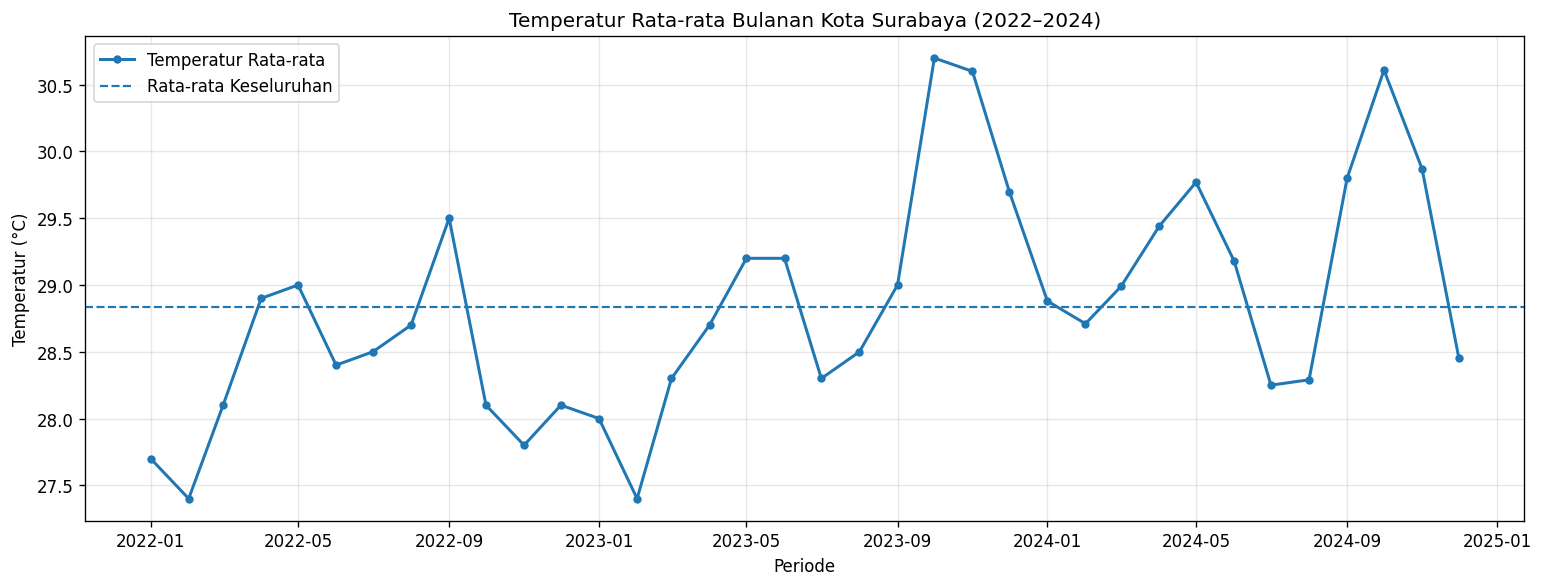

In [5]:
# ==================================================
# 5. EDA: VISUALISASI DERET WAKTU
# ==================================================

#---------------------------------------------------
# 5.1 Time Series Plot Temperatur Rata-rata
#---------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    y.index,
    y.values,
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="Temperatur Rata-rata"
)

ax.axhline(
    y.mean(),
    linestyle="--",
    linewidth=1.3,
    label="Rata-rata Keseluruhan"
)

ax.set_title("Temperatur Rata-rata Bulanan Kota Surabaya (2022–2024)")
ax.set_xlabel("Periode")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

plt.show()
plt.close(fig)

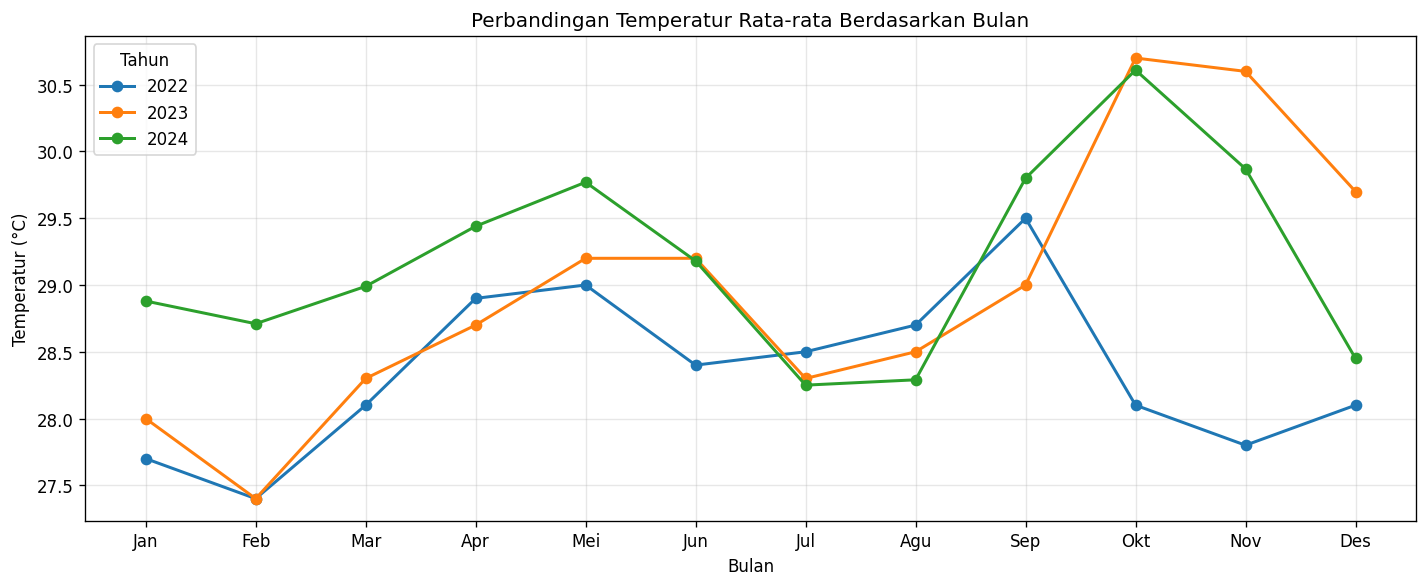

In [6]:
# ==================================================
# 6. EDA: POLA TEMPERATUR BULANAN
# ==================================================

#---------------------------------------------------
# 6.1 Perbandingan Temperatur Bulanan Antar Tahun
#---------------------------------------------------

monthly_pivot = (
    df.reset_index()
      .pivot(
          index="Bulan_num",
          columns="Tahun",
          values="Rata-rata (°C)"
      )
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
    "Jul", "Agu", "Sep", "Okt", "Nov", "Des"
]

fig, ax = plt.subplots(figsize=(12, 5))

for year in monthly_pivot.columns:
    ax.plot(
        monthly_pivot.index,
        monthly_pivot[year],
        marker="o",
        linewidth=1.8,
        label=str(year)
    )

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_title("Perbandingan Temperatur Rata-rata Berdasarkan Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Temperatur (°C)")
ax.legend(title="Tahun")
ax.grid(alpha=0.3)

fig.tight_layout()

plt.show()
plt.close(fig)

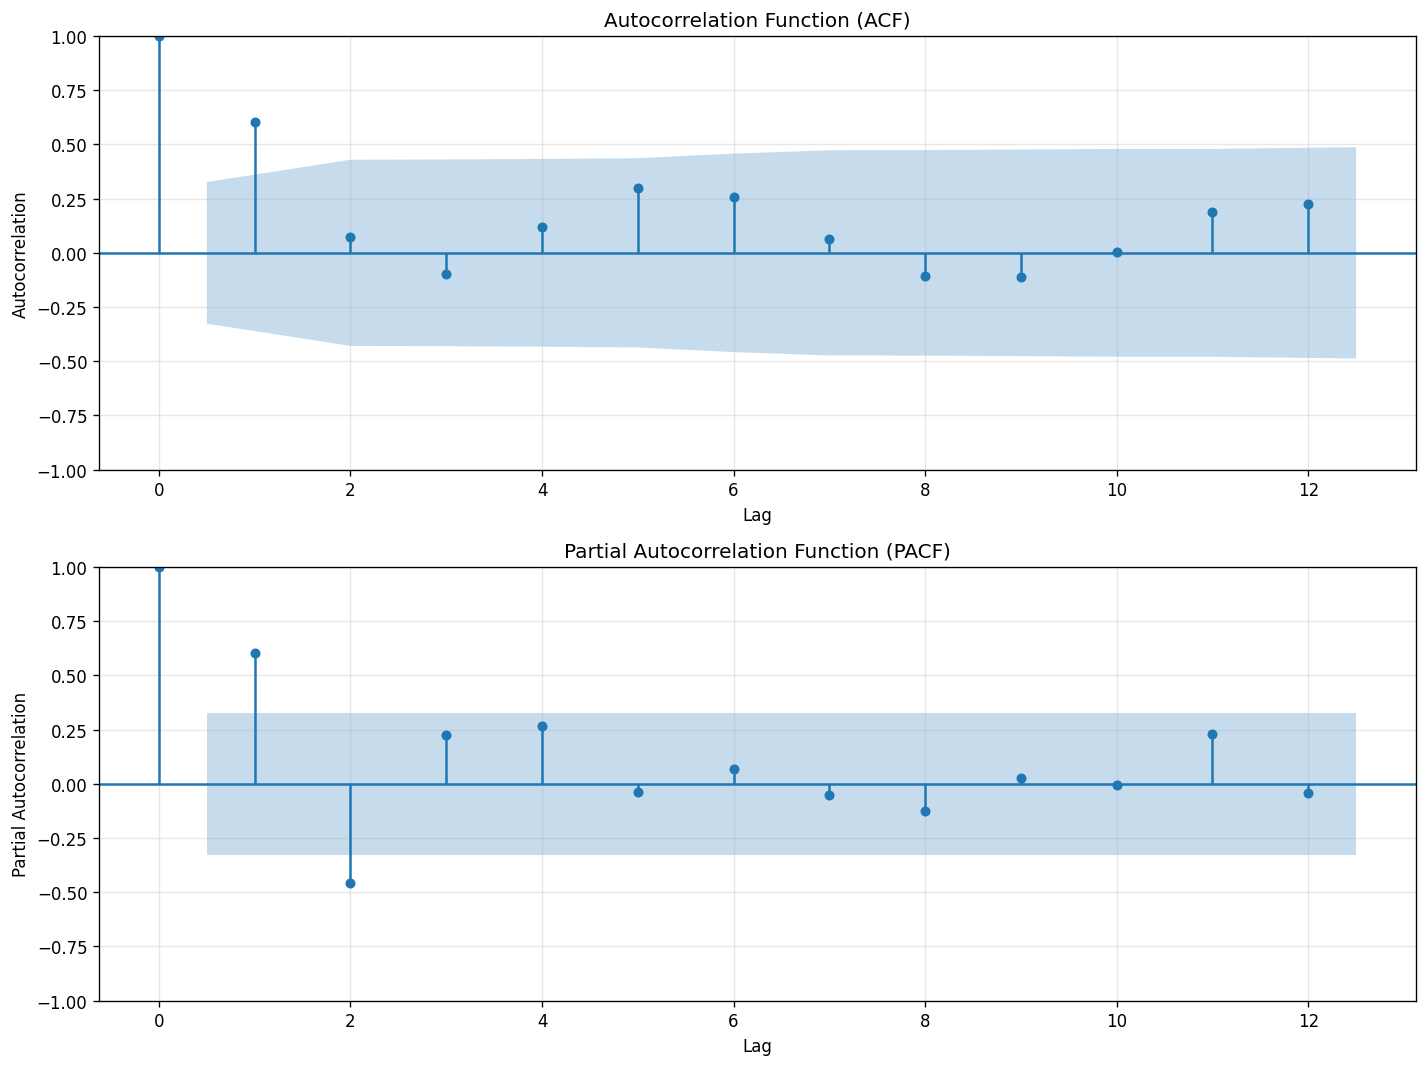

In [7]:
# ==================================================
# 7. AUTOCORRELATION ANALYSIS
# ==================================================

#---------------------------------------------------
# 7.1 Autocorrelation Function (ACF)
#---------------------------------------------------

lags = min(MAX_LAGS, len(y) // 2 - 1)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

plot_acf(
    y,
    lags=lags,
    alpha=0.05,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")

#---------------------------------------------------
# 7.2 Partial Autocorrelation Function (PACF)
#---------------------------------------------------

plot_pacf(
    y,
    lags=lags,
    alpha=0.05,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")

fig.tight_layout()

plt.show()
plt.close(fig)

In [8]:
# ==================================================
# 8. AUGMENTED DICKEY-FULLER (ADF) TEST
# ==================================================

#---------------------------------------------------
# 8.1 Pengujian ADF Level dan Trend
#---------------------------------------------------

if y.isna().any():
    raise ValueError("Deret waktu mengandung missing value.")

adf_results_list = []

for regression in ["c", "ct"]:

    result = adfuller(
        y,
        regression=regression,
        autolag="AIC"
    )

    adf_results_list.append({
        "spesifikasi": regression,
        "statistik_adf": result[0],
        "p_value": result[1],
        "lag_terpilih": result[2],
        "jumlah_observasi": result[3],
        "critical_1%": result[4]["1%"],
        "critical_5%": result[4]["5%"],
        "critical_10%": result[4]["10%"],
        "keputusan": (
            "tolak_h0"
            if result[1] < ALPHA
            else "gagal_tolak_h0"
        )
    })

adf_results = pd.DataFrame(adf_results_list)

display(adf_results)

/tmp/ipykernel_889/2333086930.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_889/2333086930.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


,spesifikasi,statistik_adf,p_value,lag_terpilih,jumlah_observasi,critical_1%,critical_5%,critical_10%,keputusan
0,c,-1.645449,0.459415,3,32,-3.653520,-2.957219,-2.617588,gagal_tolak_h0
1,ct,-5.432773,0.000031,1,34,-4.253043,-3.548590,-3.207062,tolak_h0


In [9]:
# ==================================================
# 9. KWIATKOWSKI-PHILLIPS-SCHMIDT-SHIN (KPSS) TEST
# ==================================================

#---------------------------------------------------
# 9.1 Pengujian KPSS Level dan Trend
#---------------------------------------------------

kpss_results_list = []

for regression in ["c", "ct"]:

    result = kpss(
        y,
        regression=regression,
        nlags="auto"
    )

    kpss_results_list.append({
        "spesifikasi": regression,
        "statistik_kpss": result[0],
        "p_value": result[1],
        "lag_terpilih": result[2],
        "critical_10%": result[3]["10%"],
        "critical_5%": result[3]["5%"],
        "critical_2.5%": result[3]["2.5%"],
        "critical_1%": result[3]["1%"],
        "keputusan": (
            "tolak_h0"
            if result[1] < ALPHA
            else "gagal_tolak_h0"
        )
    })

kpss_results = pd.DataFrame(kpss_results_list)

display(kpss_results)

/tmp/ipykernel_889/2419243140.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = kpss(


,spesifikasi,statistik_kpss,p_value,lag_terpilih,critical_10%,critical_5%,critical_2.5%,critical_1%,keputusan
0,c,0.585476,0.023957,2,0.347,0.463,0.574,0.739,tolak_h0
1,ct,0.084067,0.100000,0,0.119,0.146,0.176,0.216,gagal_tolak_h0


In [10]:
# ==================================================
# 10. PERBANDINGAN DAN KESIMPULAN STASIONERITAS
# ==================================================

#---------------------------------------------------
# 10.1 Penggabungan Hasil ADF dan KPSS
#---------------------------------------------------

adf_table = adf_results.set_index("spesifikasi")
kpss_table = kpss_results.set_index("spesifikasi")

comparison = []

for spec in ["c", "ct"]:

    adf_reject = adf_table.loc[spec, "p_value"] < ALPHA
    kpss_reject = kpss_table.loc[spec, "p_value"] < ALPHA

    if adf_reject and not kpss_reject:
        conclusion = "mendukung_stasioneritas"
    elif not adf_reject and kpss_reject:
        conclusion = "mendukung_nonstasioneritas"
    elif adf_reject and kpss_reject:
        conclusion = "hasil_bertentangan"
    else:
        conclusion = "belum_konklusif"

    comparison.append({
        "spesifikasi": spec,
        "ADF_p_value": adf_table.loc[spec, "p_value"],
        "ADF_keputusan": adf_table.loc[spec, "keputusan"],
        "KPSS_p_value": kpss_table.loc[spec, "p_value"],
        "KPSS_keputusan": kpss_table.loc[spec, "keputusan"],
        "kesimpulan": conclusion
    })

stationarity_comparison = pd.DataFrame(comparison)

display(stationarity_comparison)

,spesifikasi,ADF_p_value,ADF_keputusan,KPSS_p_value,KPSS_keputusan,kesimpulan
0,c,0.459415,gagal_tolak_h0,0.023957,tolak_h0,mendukung_nonstasioneritas
1,ct,0.000031,tolak_h0,0.100000,gagal_tolak_h0,mendukung_stasioneritas
